In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class State(TypedDict):
    question: str
    answer: str
    llm_answer: str
    attempts: int      # loop counter

In [2]:
def greet(state: State):
    return {"answer": "You asked: " + state["question"]}

In [3]:
import os
from dataclasses import dataclass
from langchain_ollama import ChatOllama


@dataclass
class LLMConfig:
    model: str = os.getenv("OLLAMA_MODEL", "qwen3:0.6b")        # run `ollama pull <model>` first
    base_url: str = os.getenv("OLLAMA_HOST", "http://localhost:11434")
    temperature: float = 0.2
    num_ctx: int = 4096        # context window
    num_predict: int = 1024     # max tokens to generate
    timeout: float = 120       # seconds (client timeout)


def build_llm(cfg: LLMConfig) -> ChatOllama:
    return ChatOllama(
        model=cfg.model,
        base_url=cfg.base_url,
        temperature=cfg.temperature,
        num_ctx=cfg.num_ctx,
        num_predict=cfg.num_predict,
        client_kwargs={"timeout": cfg.timeout},
    )


llm_config = LLMConfig()
llm = build_llm(llm_config)

MAX_ATTEMPTS = 3
MAX_CHARS = 150

def call_llm(state: State):
    attempts = state.get("attempts", 0)
    if attempts == 0:
        prompt = state["question"]
    else:
        # loop iteration: ask the model to shorten its previous answer
        prompt = (
            f"Rewrite this answer in one short sentence (under {MAX_CHARS} characters):\n"
            + state["llm_answer"]
        )
    response = llm.invoke(prompt)
    print(response)
    print(f"attempt {attempts + 1}: {len(response.content)} chars")
    return {"llm_answer": response.content, "attempts": attempts + 1}




def should_continue(state: State):
    """Router: decide whether to loop back or finish."""
    if len(state["llm_answer"]) <= MAX_CHARS:
        return "done"          # short enough -> stop
    if state["attempts"] >= MAX_ATTEMPTS:
        return "done"          # safety limit -> stop
    return "retry"             # too long -> loop back

In [4]:
builder = StateGraph(State)
builder.add_node("greet", greet)
builder.add_node("call_llm", call_llm)

builder.add_edge(START, "greet")
builder.add_edge("greet", "call_llm")

# The loop: after call_llm, the router picks the next node.
# "retry" goes back to call_llm, "done" ends the graph.
builder.add_conditional_edges(
    "call_llm",
    should_continue,
    {"retry": "call_llm", "done": END},
)

In [5]:
graph = builder.compile()

myState = {
    "question": "What is a graph? (in short)",
    "answer": "",
    "llm_answer": "",
    "attempts": 0,
}

result = graph.invoke(myState)
print(result)

content='A graph is a structure consisting of a set of **nodes** (points) and **edges** (connections between them). It can be **directed** (with arrows) or **undirected** (with lines), and it can represent relationships between objects, people, or elements. Examples include a tree (a connected graph with no cycles) or a complete graph (all possible connections between nodes).' additional_kwargs={} response_metadata={'model': 'qwen3:0.6b', 'created_at': '2026-11-12T11:14:30.575531527Z', 'done': True, 'done_reason': 'stop', 'total_duration': 18126925390, 'load_duration': 5937099872, 'prompt_eval_count': 19, 'prompt_eval_duration': 247117000, 'eval_count': 266, 'eval_duration': 11934148000, 'logprobs': None, 'model_name': 'qwen3:0.6b', 'model_provider': 'ollama'} id='lc_run--01a1cf77-1d4e-7d53-8731-864f2355d2b2-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 19, 'output_tokens': 266, 'total_tokens': 285}
attempt 1: 369 chars
content='A graph is a structure with node

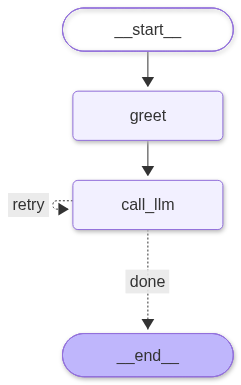

In [6]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))